# Description

Step 2 of the plan on #733: how predictable is the direction of the next
move at each horizon, and is it enough to trade after costs?

- Three models for each coin and horizon:
  - always buy: the baseline
  - momentum: bet that the move over the last horizon continues
  - logistic regression on the 17 features from `tradability.data.ipynb`
- Walk forward by year: for each year from 2022, fit on all the data before
  it, leaving out the last horizon so no training label uses a price from
  the test year
- Evaluate on non-overlapping trades in 2022-01-01 to 2026-10-01
- Compare the hit rate with p* from Exercise 1 (corrected with N_eff), and
  with p* after a cost c per trade: p* + c / (2 mean |r|)

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd

import data_utils as dutil
import predict_utils as putil

## Config

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVAL = "5m"
START = "2020-01-01"
END = "2026-10-01"
HORIZONS = ["5m", "15m", "1h", "4h", "1d"]
# Fit on the years before each of these and test on it.
TEST_YEARS = [2022, 2023, 2024, 2025, 2026]
# Cost of a round trip: 10 bp, as in the plan on #733.
COST = 0.001
# Past return over the same length as the horizon, for momentum.
MOMENTUM_COLUMNS = {
    "5m": "ret_1",
    "15m": "ret_3",
    "1h": "ret_12",
    "4h": "ret_48",
    "1d": "mom_1d",
}
MODELS = ["always_buy", "momentum", "logistic"]

## Data, features, labels

In [3]:
clean = {}
for symbol in SYMBOLS:
    raw = dutil.load_ohlcv(symbol, START, END, interval=INTERVAL)
    clean[symbol] = dutil.clean_bars(raw, interval=INTERVAL)
other = {"BTCUSDT": "ETHUSDT", "ETHUSDT": "BTCUSDT"}
features = {}
labels = {}
for symbol in SYMBOLS:
    features[symbol] = dutil.compute_features(
        clean[symbol],
        other=clean[other[symbol]],
        other_name=other[symbol][:3].lower(),
        interval=INTERVAL,
    )
    labels[symbol] = dutil.compute_labels(
        clean[symbol], HORIZONS, interval=INTERVAL
    )

## Predict and evaluate

In [4]:
test_start = f"{TEST_YEARS[0]}-01-01"
rows = []
trades = {}
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        pos = {
            "always_buy": putil.predict_always_buy(features[symbol]),
            "momentum": putil.predict_momentum(
                features[symbol], MOMENTUM_COLUMNS[horizon]
            ),
            "logistic": putil.predict_logistic(
                features[symbol],
                labels[symbol],
                horizon,
                TEST_YEARS,
                interval=INTERVAL,
            ),
        }
        # One trade every horizon, in the test years only.
        sample = dutil.sample_non_overlapping(
            labels[symbol], horizon, interval=INTERVAL
        )
        sample = sample[sample.index >= test_start]
        fwd_ret = sample[f"fwd_ret_{horizon}"]
        for model in MODELS:
            trades[(symbol, horizon, model)] = pd.DataFrame(
                {"pos": pos[model].reindex(sample.index), "fwd_ret": fwd_ret}
            )
            stats = putil.evaluate_positions(
                pos[model].reindex(sample.index), fwd_ret, cost=COST
            )
            rows.append(
                {"symbol": symbol, "horizon": horizon, "model": model, **stats}
            )
results = pd.DataFrame(rows).set_index(["symbol", "horizon", "model"])
results.round(4)

n  hit_rate  weighted_hit_rate  \
symbol  horizon model                                               
BTCUSDT 5m      always_buy  497991.0    0.5004             0.5013   
                momentum    496713.0    0.4880             0.4971   
                logistic    495975.0    0.5184             0.5011   
        15m     always_buy  166364.0    0.5002             0.5022   
                momentum    166274.0    0.4767             0.4852   
                logistic    165693.0    0.5208             0.5060   
        1h      always_buy   41601.0    0.5037             0.5043   
                momentum     41588.0    0.4698             0.4874   
                logistic     41433.0    0.5227             0.5030   
        4h      always_buy   10402.0    0.5087             0.5083   
                momentum     10401.0    0.4592             0.4872   
                logistic     10360.0    0.5265             0.5117   
        1d      always_buy    1731.0    0.4986             0.5197   
                momentum      1729.0    0.4841             0.5120   
                logistic      1724.0    0.5012             0.5132   
ETHUSDT 5m      always_buy  497912.0    0.5009             0.5006   
                momentum    496511.0    0.4870             0.5000   
                logistic    495898.0    0.5204             0.4977   
        15m     always_buy  166234.0    0.5014             0.5011   
                momentum    166015.0    0.4743             0.4906   
                logistic    165562.0    0.5230             0.5005   
        1h      always_buy   41583.0    0.5071             0.5021   
                momentum     41552.0    0.4730             0.4992   
                logistic     41416.0    0.5213             0.4981   
        4h      always_buy   10397.0    0.5073             0.5039   
                momentum     10391.0    0.4725             0.5024   
                logistic     10355.0    0.5195             0.5077   
        1d      always_buy    1732.0    0.5064             0.5097   
                momentum      1731.0    0.4772             0.4912   
                logistic      1725.0    0.5206             0.5194   

                                  n_eff  p_star  p_star_cost  gross_bps  \
symbol  horizon model                                                     
BTCUSDT 5m      always_buy  186102.5013  0.5019       1.0125     0.0249   
                momentum    185803.8316  0.5019       1.0118    -0.0578   
                logistic    185255.4987  0.5019       1.0126     0.0220   
        15m     always_buy   62329.8261  0.5033       0.8004     0.0738   
                momentum     62300.5737  0.5033       0.8003    -0.4991   
                logistic     62060.8512  0.5033       0.8005     0.2024   
        1h      always_buy   15993.0309  0.5065       0.6554     0.2908   
                momentum     15987.4649  0.5065       0.6554    -0.8441   
                logistic     15920.1107  0.5065       0.6555     0.1989   
        4h      always_buy    4300.4375  0.5125       0.5857     1.1352   
                momentum      4299.8824  0.5125       0.5857    -1.7426   
                logistic      4278.1725  0.5126       0.5858     1.5969   
        1d      always_buy     800.3086  0.5291       0.5569     7.0861   
                momentum       799.4882  0.5291       0.5569     4.3290   
                logistic       796.2870  0.5291       0.5569     4.7523   
ETHUSDT 5m      always_buy  187708.7377  0.5019       0.8900     0.0160   
                momentum    187261.5693  0.5019       0.8896     0.0005   
                logistic    186942.5905  0.5019       0.8897    -0.0589   
        15m     always_buy   62518.9209  0.5033       0.7277     0.0480   
                momentum     62440.1145  0.5033       0.7276    -0.4205   
                logistic     62260.9076  0.5033       0.7275     0.0213   
        1h      always_buy   16056.9730  0.5065       0.6180     0.1886   
                momentum  

## Hit rate vs horizon

- Solid lines: hit rate of each model
- Dashed lines: weighted hit rate, the share of the total |r| traded in the
  right direction. The PnL before costs is positive only above 0.5
- Black line: p* with N_eff (95% chance of profit, no costs)

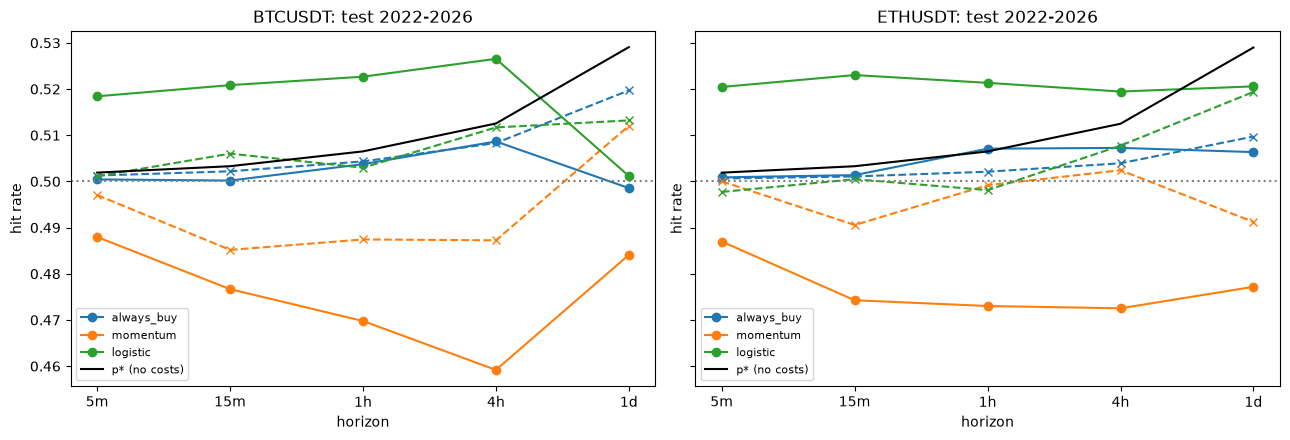

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, symbol in zip(axes, SYMBOLS):
    for i, model in enumerate(MODELS):
        sub = results.loc[(symbol, slice(None), model)]
        color = f"C{i}"
        ax.plot(HORIZONS, sub["hit_rate"], marker="o", color=color, label=model)
        ax.plot(
            HORIZONS,
            sub["weighted_hit_rate"],
            marker="x",
            linestyle="--",
            color=color,
        )
    p_star = results.loc[(symbol, slice(None), "always_buy"), "p_star"]
    ax.plot(HORIZONS, p_star, color="black", label="p* (no costs)")
    ax.axhline(0.5, color="gray", linestyle=":")
    ax.set_title(f"{symbol}: test 2022-2026")
    ax.set_xlabel("horizon")
    ax.set_ylabel("hit rate")
    ax.legend(fontsize=8)
plt.tight_layout()

## Why a 52% hit rate makes no money

Compare the size of the moves the logistic model gets right and wrong.

In [6]:
rows = []
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        df = trades[(symbol, horizon, "logistic")].dropna()
        df = df[df["fwd_ret"] != 0]
        is_hit = df["pos"] * df["fwd_ret"] > 0
        rows.append(
            {
                "symbol": symbol,
                "horizon": horizon,
                "mean_abs_ret_hits_bps": df.loc[is_hit, "fwd_ret"].abs().mean()
                * 1e4,
                "mean_abs_ret_misses_bps": df.loc[~is_hit, "fwd_ret"]
                .abs()
                .mean()
                * 1e4,
                "share_long": (df["pos"] > 0).mean(),
            }
        )
pd.DataFrame(rows).set_index(["symbol", "horizon"]).round(3)

mean_abs_ret_hits_bps  mean_abs_ret_misses_bps  share_long
symbol  horizon                                                            
BTCUSDT 5m                       9.463                   10.142       0.478
        15m                     16.346                   17.346       0.526
        1h                      32.290                   34.941       0.597
        4h                      66.369                   70.438       0.678
        1d                     184.190                  175.520       0.900
ETHUSDT 5m                      12.331                   13.506       0.464
        15m                     21.338                   23.354       0.519
        1h                      42.862                   47.038       0.613
        4h                      90.173                   94.504       0.683
        1d                     244.024                  245.204       0.892

## Costs

- Left: hit rate needed for a 95% chance of profit, without and with a 10 bp
  cost per trade
- Right: average PnL per trade before costs. A strategy breaks even when
  this is equal to the cost (10 bp, red line)

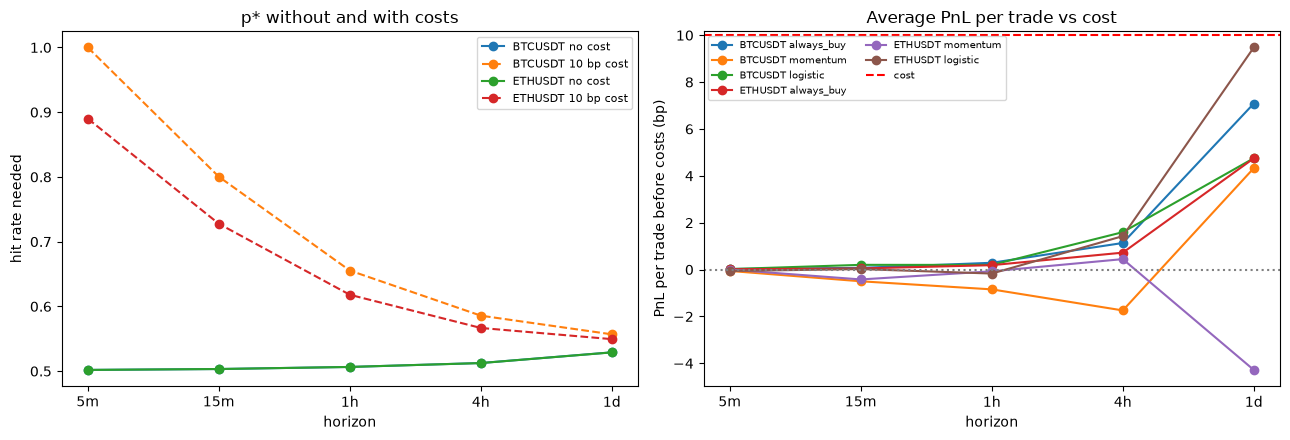

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for symbol in SYMBOLS:
    sub = results.loc[(symbol, slice(None), "always_buy")]
    axes[0].plot(HORIZONS, sub["p_star"], marker="o", label=f"{symbol} no cost")
    axes[0].plot(
        HORIZONS,
        sub["p_star_cost"].clip(upper=1.0),
        marker="o",
        linestyle="--",
        label=f"{symbol} 10 bp cost",
    )
axes[0].set_xlabel("horizon")
axes[0].set_ylabel("hit rate needed")
axes[0].set_title("p* without and with costs")
axes[0].legend(fontsize=8)
gross = results["gross_bps"].unstack("model")
for symbol in SYMBOLS:
    for model in MODELS:
        axes[1].plot(
            HORIZONS,
            gross.loc[symbol, model].loc[HORIZONS],
            marker="o",
            label=f"{symbol} {model}",
        )
axes[1].axhline(COST * 1e4, color="red", linestyle="--", label="cost")
axes[1].axhline(0, color="gray", linestyle=":")
axes[1].set_xlabel("horizon")
axes[1].set_ylabel("PnL per trade before costs (bp)")
axes[1].set_title("Average PnL per trade vs cost")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()

## Observations

- Short moves tend to reverse. Momentum is right only 46-49% of the time
  from 5m to 4h, so betting on a reversal would be right 51-54% of the
  time. At the shortest horizons part of this may be bid-ask bounce in the
  close prices
- The logistic regression has a 52% hit rate at every horizon from 5m to
  4h, above p*. But it makes almost no money before costs (0-2 bp per
  trade). The moves it gets wrong are 6-10% bigger than the ones it gets
  right (BTC 1h: 35 bp vs 32 bp), so its weighted hit rate is only about
  0.50. A hit rate above p* is not enough: p* assumes that being right does
  not depend on the size of the move
- At 1d the logistic regression is long 90% of the time, so it is close to
  always buying
- With a 10 bp cost per trade, the hit rate needed for a 95% chance of
  profit is over 100% at 5m for BTC (impossible), 73-80% at 15m,
  62-66% at 1h, 57-59% at 4h, and 55-56% at 1d. Without costs it is 50.2%
  to 52.9%. Costs push the best horizon towards the longest ones
- Before costs, the best model makes under 0.3 bp per trade from 5m to 1h,
  1.6 bp at 4h, and 9.5 bp at 1d. It is below the 10 bp cost everywhere, so
  no model makes money after costs in 2022-2026. The closest is the
  logistic regression on ETH at 1d (9.5 bp before costs), on only 1,725
  trades
- Results at 1d are noisy: about 1,730 trades, and the hit rate and the
  weighted hit rate differ a lot